# Итоги исследования

## Как отбор данных меняет оценку ухода на второй круг

Вопрос исследования: какую популяцию представляет оценка модели после
требования полноты C40 и метаданных, и что теряется за ее пределами?
Это исследование опубликованных записей с исходной меткой GoA.
Оно не является подтверждением пригодности системы для реального прогноза.

Условный recall корректен для задачи на событиях с пригодным C40. Source —
отдельный более широкий знаменатель сравнения, а не автоматически лучшая
целевая популяция. Само ограничение выборки не доказывает ошибку; перенос
условного результата на всю source требует явного учета покрытия.

Разделяем исходный описательный аудит 01–05, зафиксированное моделирование
06–08 и исследовательские проверки после просмотра test 09–11.
Этот ноутбук собирает результаты из отчетов; новые модели не выбираются.
Подробное ревью — `reports/research_review.md`; расширенный обзор —
`literature/04_evaluation_review.md`. Публикационная рукопись хранится отдельно
от репозитория исследования.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/selection_evaluation_verification.json').exists():
    if ROOT==ROOT.parent:raise FileNotFoundError('Сначала выполните 10–11')
    ROOT=ROOT.parent
R=ROOT/'reports';F=ROOT/'figures'
selection=pd.read_csv(R/'selection_summary.csv').set_index('stage')
population=pd.read_csv(R/'selection_evaluation_population.csv').set_index('population')
metrics=pd.read_csv(R/'selection_evaluation_metrics.csv')
reference=pd.read_csv(R/'comparison_reference_metrics.csv').query('split=="test"').set_index('model')
intervals=pd.read_csv(R/'comparison_block_intervals.csv')
ranking=pd.read_csv(R/'comparison_equal_budget.csv')
checks={n:json.loads((R/(n+'_verification.json')).read_text(encoding='utf-8'))
 for n in ['selection_evaluation','comparison']}
assert checks['selection_evaluation']['coverage_identity_passed']
assert checks['comparison']['coefficient_replay_passed'] and checks['comparison']['weighted_metric_parity_passed']
core=metrics[metrics.scenario.eq('C40_context')].set_index('model')
source_goa=int(population.loc['source_landing_period','goa'])
scored_goa=int(population.loc['scored_test','goa'])
table=pd.DataFrame([{
 'Модель':name,'AP внутри test':reference.loc[name,'AP'],
 'Найдено GoA':int(core.loc[name,'tp']),
 'Пропущено внутри покрытия':int(core.loc[name,'fn_in_coverage']),
 'GoA вне покрытия':source_goa-scored_goa,
 'Recall внутри покрытия, %':100*core.loc[name,'recall_in_coverage'],
 'Найдено от исходных GoA, %':100*core.loc[name,'found_fraction_source']}
 for name in ['geometry','geometry_aircraft']])
table.to_csv(R/'study_summary.csv',index=False)
display(table.style.format(precision=5))

,Модель,AP внутри test,Найдено GoA,Пропущено внутри покрытия,GoA вне покрытия,"Recall внутри покрытия, %","Найдено от исходных GoA, %"
0,geometry,0.00376,768,971,1071,44.16331,27.33096
1,geometry_aircraft,0.00398,35,1704,1071,2.01265,1.24555


## 1. Покрытие ограничивает область оценки

Положительные события вне покрытия не включены в обычные FN модели.
Тем не менее для сочетания допуска записи и классификатора они не обнаружены.
Общий знаменатель показывает этот разрыв, не приписывая модели неизвестные
scores. Даже идеальное обнаружение внутри существующего покрытия ограничено
долей исходных GoA, попавших в него.

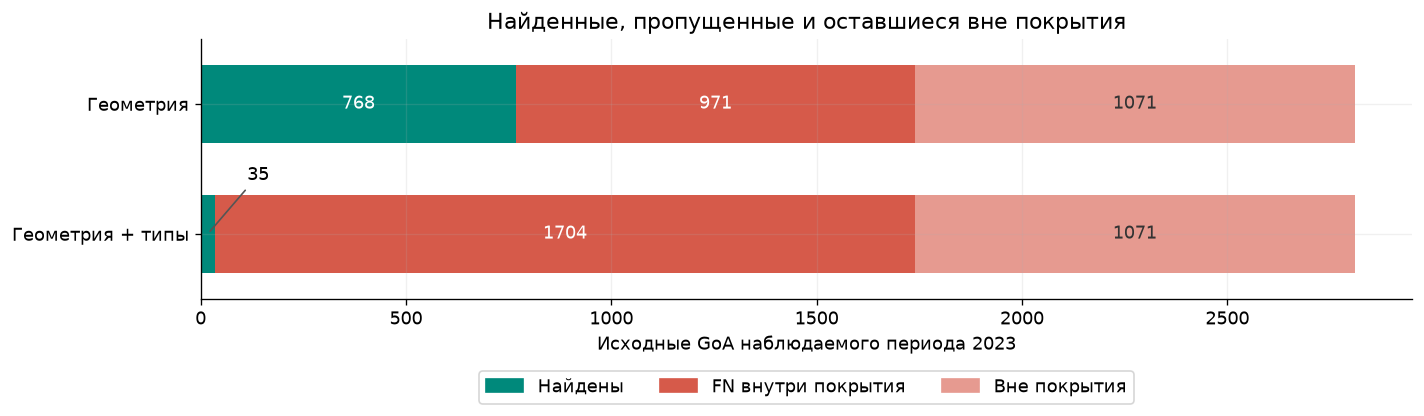

Исходные validation-пороги у моделей разные; рисунок показывает знаменатель оценки, а не изолированный эффект типов.

In [2]:
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
fig,ax=plt.subplots(figsize=(12,4))
for i,name in enumerate(['geometry','geometry_aircraft']):
    values=[int(core.loc[name,'tp']),int(core.loc[name,'fn_in_coverage']),source_goa-scored_goa]
    assert sum(values)==source_goa
    left=0
    for v,color in zip(values,['#00897B','#D65A4A','#E69A90']):
        ax.barh(i,v,left=left,color=color,height=.6)
        if v>60:ax.text(left+v/2,i,str(v),ha='center',va='center',color='white' if color!='#E69A90' else '#333333')
        left+=v
    if values[0]<=60:ax.annotate(str(values[0]),(values[0]/2,i),xytext=(140,i-.38),
                                 arrowprops={'arrowstyle':'-','color':'#555555'},ha='center',va='bottom')
ax.set_yticks([0,1],['Геометрия','Геометрия + типы']);ax.invert_yaxis()
ax.set(xlabel='Исходные GoA наблюдаемого периода 2023',title='Найденные, пропущенные и оставшиеся вне покрытия')
ax.set_ylim(1.5,-.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c,label=t) for c,t in zip(['#00897B','#D65A4A','#E69A90'],
 ['Найдены','FN внутри покрытия','Вне покрытия'])],loc='lower center',bbox_to_anchor=(.5,-.44),ncol=3)
plt.tight_layout()
for ext in ['png','svg']:plt.savefig(F/f'37_source_goa_outcomes.{ext}',bbox_inches='tight')
plt.show()
display(Markdown('Исходные validation-пороги у моделей разные; рисунок показывает знаменатель оценки, а не изолированный эффект типов.'))

## 2. Устойчивый небольшой сигнал и его границы

Ориентир частоты аэропорта рассчитан только на train. Для него не используются
метки test. При одинаковом числе ранговых позиций модели не имеют универсального
порядка качества. Интервалы разных блоков относятся к фиксированным моделям,
без переобучения и без полной модели зависимости по самолетам.

In [3]:
display(reference[['AP','ROC_AUC','Brier']].style.format(precision=7))
q=intervals[intervals.metric.eq('AP')&intervals.comparison.eq('geometry_aircraft - geometry')]
display(q[['block_weeks','estimate','lower','upper','valid_replicates']].style.format(precision=7))
display(ranking[ranking.budget_test.isin([.01,.05])][['model','budget_test','positions','expected_tp','recall']].style.format(precision=5))
assert len(q)==3
facts={'status':'retrospective study; extensions exploratory after test inspection',
 'source_rows_all':int(selection.loc['source','rows']),'source_goa_all':int(selection.loc['source','goa']),
 'final_rows_all':int(selection.loc['final','rows']),'final_goa_all':int(selection.loc['final','goa']),
 'source_rows_period':int(population.loc['source_landing_period','rows']),'source_goa_period':source_goa,
 'scored_goa_period':scored_goa,'positive_coverage_period':scored_goa/source_goa,
 'uncovered_goa_period':source_goa-scored_goa,'metadata_bundle_rows_test':int(metrics.query('scenario=="raw_metadata_bundle"').rows.iloc[0]),
 'metadata_bundle_goa_test':int(metrics.query('scenario=="raw_metadata_bundle"').goa.iloc[0]),
 'aircraft_AP_difference_positive_all_block_lengths':bool(q.lower.gt(0).all()),
 'geometry_beats_airport_prior_AP':bool(reference.loc['geometry','AP']>reference.loc['airport_prior','AP']),
 'operational_availability_verified':False,'source_model_AP_identified':False,'new_training_performed':False}
(R/'study_summary.json').write_text(json.dumps(facts,ensure_ascii=False,indent=2),encoding='utf-8')
text=f"""# Основной результат исследования

За наблюдаемый период 2023 модель оценивается на {scored_goa} из {source_goa}
исходных GoA: покрытие {100*scored_goa/source_goa:.2f}%. Остальные
{source_goa-scored_goa} положительных событий находятся вне ее области оценки.
При исходном пороге geometry находит {int(core.loc['geometry','tp'])} GoA:
{100*core.loc['geometry','recall_in_coverage']:.2f}% внутри test и
{100*core.loc['geometry','found_fraction_source']:.2f}% относительно source периода.

Полный набор метаданных оставляет {facts['metadata_bundle_rows_test']} test-записи
и {facts['metadata_bundle_goa_test']} GoA: AP не определена, положительное покрытие нулевое.
Требование typecode и описания оставляет {100*float(metrics.query('scenario=="raw_aircraft_class"').positive_coverage_test.iloc[0]):.2f}% GoA test,
сохраняя AP близкой к исходной. Изменения AP малы и разнонаправленны;
гипотеза о неизбежном завышении AP не подтверждена.

Geometry не превосходит аэропортовый ориентир по точечной AP test.
Geometry_aircraft имеет небольшой положительный прирост AP относительно geometry;
он сохраняет знак интервала при блоках 1/2/4 недели. Это ограниченный результат
ранжирования, без универсального преимущества при каждом бюджете.

Основной эмпирический вклад — связь цепочки отбора, календарного покрытия и
знаменателя оценки. Не доказаны причины пропусков, причинный эффект типов,
эксплуатационная пригодность и AP C40-модели на всей source.
Расширения после просмотра test остаются исследовательскими.
"""
(R/'study_findings.md').write_text(text,encoding='utf-8');display(Markdown(text))

,AP,ROC_AUC,Brier
model,,,
airport_prior,0.0038078,0.5639007,0.0031711
geometry,0.0037587,0.5623436,0.0031711
geometry_aircraft,0.0039796,0.5722968,0.0031710


,block_weeks,estimate,lower,upper,valid_replicates
0,1,0.0002209,0.0000273,0.0004607,1000
6,2,0.0002209,0.0000308,0.0004737,1000
12,4,0.0002209,0.0000210,0.0004866,1000


,model,budget_test,positions,expected_tp,recall
2,airport_prior,0.01000,5465,23.11151,0.01329
3,airport_prior,0.05000,27328,115.57022,0.06646
6,geometry,0.01000,5465,18.00000,0.01035
7,geometry,0.05000,27328,108.00000,0.06210
10,geometry_aircraft,0.01000,5465,14.00000,0.00805
11,geometry_aircraft,0.05000,27328,124.00000,0.07131


# Основной результат исследования

За наблюдаемый период 2023 модель оценивается на 1739 из 2810
исходных GoA: покрытие 61.89%. Остальные
1071 положительных событий находятся вне ее области оценки.
При исходном пороге geometry находит 768 GoA:
44.16% внутри test и
27.33% относительно source периода.

Полный набор метаданных оставляет 92 test-записи
и 0 GoA: AP не определена, положительное покрытие нулевое.
Требование typecode и описания оставляет 93.67% GoA test,
сохраняя AP близкой к исходной. Изменения AP малы и разнонаправленны;
гипотеза о неизбежном завышении AP не подтверждена.

Geometry не превосходит аэропортовый ориентир по точечной AP test.
Geometry_aircraft имеет небольшой положительный прирост AP относительно geometry;
он сохраняет знак интервала при блоках 1/2/4 недели. Это ограниченный результат
ранжирования, без универсального преимущества при каждом бюджете.

Основной эмпирический вклад — связь цепочки отбора, календарного покрытия и
знаменателя оценки. Не доказаны причины пропусков, причинный эффект типов,
эксплуатационная пригодность и AP C40-модели на всей source.
Расширения после просмотра test остаются исследовательскими.


## 3. Что можно утверждать в статье

| Утверждение | Статус |
| --- | --- |
| Отбор непропорционально сохраняет исходные GoA | Подтверждено на полном опубликованном массиве |
| Требования к метаданным меняют календарную поддержку | Подтверждено прямыми подсчетами |
| Recall на отобранной базе отличается от доли найденных исходных GoA | Подтверждено точным соединением и арифметическим тождеством |
| Типы дают небольшой прирост AP фиксированных моделей | Подтверждено условно выбранному протоколу; расширенная устойчивость исследовательская |
| Отбор всегда завышает AP | Не подтверждено нашими сценариями |
| Мы создали пригодную систему раннего предупреждения | Не установлено |
| Результат является первым в литературе | Не установлено |

Статья должна описывать изменение популяции и смысла оценки, с baseline как
проверяемым примером. Для нового выбора моделей потребуется независимый
финальный период. Оценка перспектив публикации зависит от издания и рецензирования.